In [42]:
x = np.arange(0,1, 0.01)
y = np.tanh(np.arctanh(x))
#x = np.arange(-10,10, 0.01)
#y = np.arctan(x)

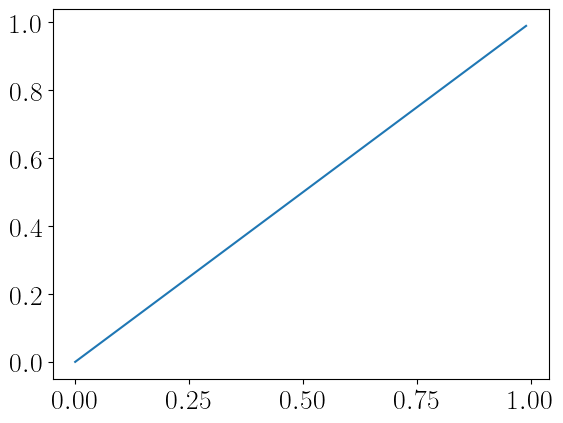

In [43]:
plt.plot(x,y)
plt.show()

In [2]:
import warnings
warnings.filterwarnings('ignore')
#############################################
#BASIC PACKAGES
import sys,time,os,pickle
from copy import deepcopy as dcopy
import healpy as hp
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

#############################################
#PATH TO SCRIPTS FOLDER
path = '/data/AMARINS/LSSxHI-CODES/scripts/'
sys.path.insert(1, path)
import cross_functions_theory      as cxft
import cross_functions_simulations as cxfs
# it's required healpy  (https://healpy.readthedocs.io/en/latest/index.html)
import handling_data               as hdata
import pandas as pd
#############################################
## MATPLOTLIB FEATURES
from matplotlib import cm
font = {'weight' : 'bold','size'   : 22}
mpl.rc('font', **font)
mpl.rc('font',   size=209)  #set defaults so that the plots are readable
mpl.rc('axes',   titlesize=20)
mpl.rc('axes',   labelsize=20)
mpl.rc('xtick',  labelsize=20)
mpl.rc('ytick',  labelsize=20)
mpl.rc('legend', fontsize =20)
mpl.rc('figure', titlesize=20)
mpl.rc('text',   usetex=True)
## FURTHER MATPLOTLIB FEATURES
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
#colors = ["#ffffcc", "#a1dab4", "#41b6c4", "#2c7fb8", "#253494"]
colors = ['#ff0000', "#41b6c4", '#0000ff']
my_cmap = ListedColormap(colors, name="my_cmap")
#my_cmap_r = my_cmap.reversed()
#############################################
## NAMASTER (https://namaster.readthedocs.io/en/latest/)
import pymaster as nmt
del_l  = 30
nside  = 256
##############################
b    = nmt.NmtBin.from_nside_linear(nside, nlb=del_l)
leff = b.get_effective_ells()
feff = leff*(leff+1)/2/np.pi


sys.path.insert(1, '/data/AMARINS/chisel/scripts')    
import Extension4BINGO   as cs
import load_standard_params as loadparams
#import pyMRS as pymrs
import statcosmo as statc

In [3]:
def get_hibins_from_gbin(_index_=None):
    if _index_==0:
        return np.array([0,1,2,3])
    elif _index_==1:
        return np.array([4,5,6,7,8,9])
    elif _index_==2:
        return np.array([10,11,12,13,14])
    elif _index_==3:
        return np.array([15,16,17,18])
    elif _index_==4:
        return np.array([18,19,20,21])
    elif _index_==5:
        return np.array([22,23,24])
    elif _index_==6:
        return np.array([25,26,27])        
    elif _index_==7:
        return np.array([28,29])       
    else:
        return np.array([28,29])    

In [4]:
with open("tf_data.pkl", "rb") as f:
    TF_dict_hi = pickle.load(f)
#TF_dict_hi[1]["tf_hi"]["tf"]

In [5]:
gbin=7
fact = 1#l*(l+1)/2/np.pi
################################################
#hbin   = get_hibins_from_gbin(1)[index_bin]
TF_hi  = TF_dict_hi[gbin]['tf_hi']['tf']
TF_no  = TF_dict_hi[gbin]['tf_no']['tf']
CXproc = TF_dict_hi[gbin]['CX']
#CXsims = dict_all['sim0']['cl_cross_sim'][1:,:]
#CXsims = CXsims[hbin,:]
CXthr = np.loadtxt('/data/AMARINS/LSSxHI-DATA/theoretical/GCxHI/LSST_bin{b}_40_0001_HIxDENSITY_cl_LOWZ.txt'.format(b=gbin) ).T[1:,:] 
#CXthr = CXthr[hbin,:]

7 29


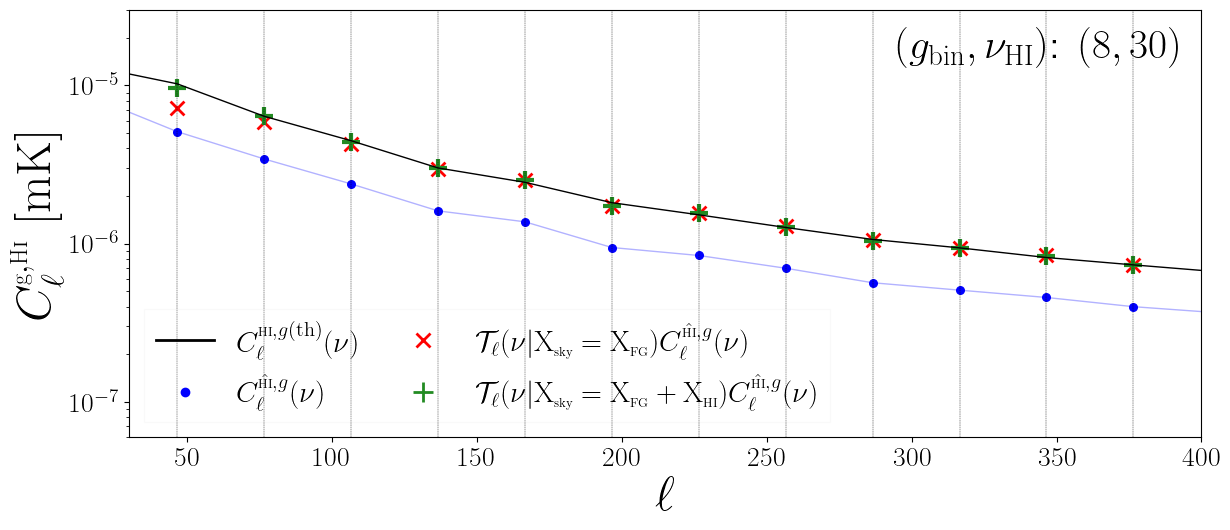

In [285]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
index_bin=1
hbin   = get_hibins_from_gbin(gbin)[index_bin]
l = np.arange(3*256)#leff[filter_ell]
print(gbin,hbin)
##################################################################
clrec    = b.bin_cell( fact*CXproc[hbin,:] )
cldeb_no = b.bin_cell( fact*CXproc[hbin,:]*TF_no[hbin,:] )
cldeb_hi = b.bin_cell( fact*CXproc[hbin,:]*TF_hi[hbin,:] )
clthr    = b.bin_cell( fact*CXthr[hbin,:] )
#
ax.plot(   leff, clthr   , color='black'      , lw=1)
ax.plot(   leff, clrec   , color='blue'       , lw=1, alpha=0.3)
ax.scatter(leff, clrec   , color='blue'       , s=30)
ax.scatter(leff, cldeb_no, color='red'        , s=100, lw=2, marker='x')
ax.scatter(leff, cldeb_hi, color='forestgreen', s=150, lw=3, marker='+')
##################################################################
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylim(0.6e-7,3e-5)  
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}\ \textrm{[mK]}$', fontsize=35)
ax.set_xlabel(r'$\ell$', fontsize=35)
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
###########################################################
ax.legend([Patch(visible=False) ], [r"$g_{\rm bin}\ \times\ \nu_{\rm HI}$: "+"{} x {}".format(gbin+1,hbin+1)], ncols=1,
         fontsize=21, loc='upper right',framealpha=0.1, fancybox=False,
         #handletextpad=0.8, 
         columnspacing=1.1)

#ax  = plt.subplot(grid[1]) 
custom_lines = [
                Line2D([], [], color='black'       , linewidth=2, linestyle='solid'),    
                Line2D([], [], color='blue'        , marker='o' , linestyle='None', markersize=5, markeredgewidth=2),        
                Line2D([], [], color='red'         , marker='x' , linestyle='None', markersize=10, markeredgewidth=2),        
                Line2D([], [], color='forestgreen' , marker='+' , linestyle='None', markersize=15, markeredgewidth=2),            
               #plot_rec
               ]
ax  = plt.subplot(grid[0]) 
ax.legend(custom_lines, [r'$C_\ell^{\textrm{\small HI},g {\rm \small{(th)} }}(\nu) $',
                         r'$C_\ell^{\hat{\textrm{\small HI}},g}(\nu) $',                         
                         r'$\mathcal{T}_\ell(\nu|{\rm X_\textrm{\small  sky}=X_\textrm{\small  FG}})C_\ell^{\hat{\textrm{\small HI}},g}(\nu) $',
                         r'$\mathcal{T}_\ell(\nu|{\rm X_\textrm{\small  sky}=X_\textrm{\small  FG}+X_\textrm{\small  HI}})C_\ell^{\hat{\textrm{\small HI}},g}(\nu) $',
                        ], ncols=2,
         fontsize=21, loc='lower left',framealpha=0.1, fancybox=False,columnspacing=1.1)
###########################################################
ax.text(x=295    , y=1.5e-5, s=r"$(g_{\rm bin},\nu_{\rm HI})$: "+ r"$(" +r"{},{}".format(gbin+1,hbin+1)+r")$", 
        fontdict={'family': 'serif', 'color':  None,  'weight': 'bold','size': 30})
###########################################################
plt.show()

In [64]:
get_hibins_from_gbin(gbin)

array([4, 5, 6, 7, 8, 9])

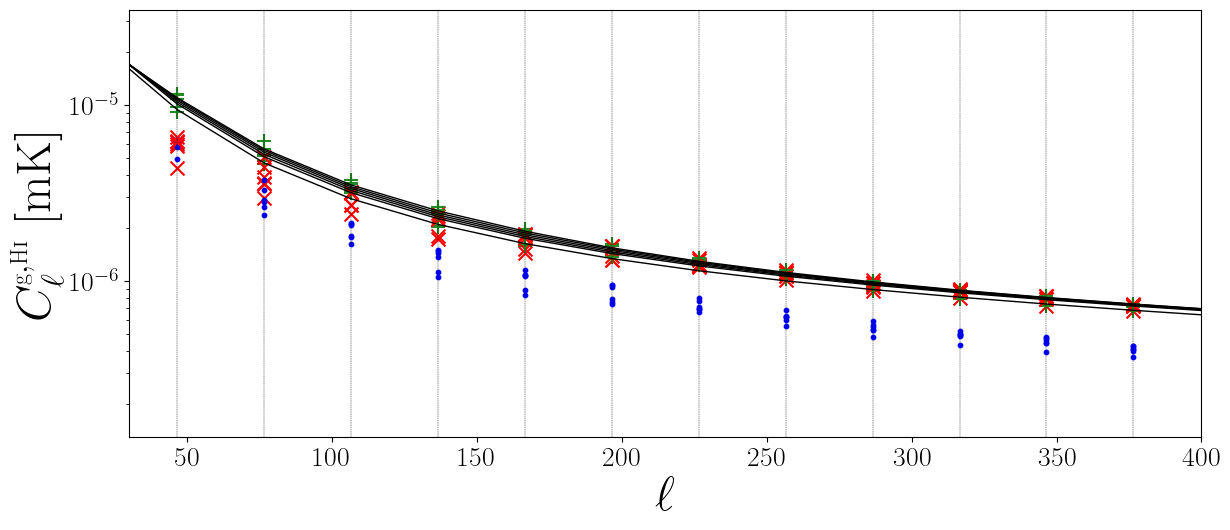

In [67]:
fig   = plt.figure()
grid  = plt.GridSpec(1,1,top=1.0,right=1.8, wspace=0.03, hspace=0.35)
############################################################
ax  = plt.subplot(grid[0]) 
#
for hbin in get_hibins_from_gbin(gbin):
    l = np.arange(3*256)#leff[filter_ell]
    #print(gbin,hbin)
    clrec    = b.bin_cell( fact*CXproc[hbin,:] )
    cldeb_no = b.bin_cell( fact*CXproc[hbin,:]*TF_no[hbin,:] )
    cldeb_hi = b.bin_cell( fact*CXproc[hbin,:]*TF_hi[hbin,:] )
    clthr    = b.bin_cell( fact*CXthr[hbin,:] )
    #
    ax.plot(   leff, clthr, color='black', lw=1)
    ax.scatter(leff, clrec, color='blue', s=10)
    ax.scatter(leff, cldeb_no, color='red', s=100, marker='x')
    ax.scatter(leff, cldeb_hi, color='forestgreen', s=100, marker='+')
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}\ \textrm{[mK]}$', fontsize=35)
ax.set_xlabel(r'$\ell$', fontsize=35)
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
############################################
plt.show()

In [71]:
import cmcrameri.cm as cmc

In [191]:
gbin=7
fact = 1#l*(l+1)/2/np.pi
################################################
#hbin   = get_hibins_from_gbin(1)[index_bin]
TF_hi  = TF_dict_hi[gbin]['tf_hi']['tf']
TF_no  = TF_dict_hi[gbin]['tf_no']['tf']
CXproc = TF_dict_hi[gbin]['CX']
#CXsims = dict_all['sim0']['cl_cross_sim'][1:,:]
#CXsims = CXsims[hbin,:]
CXthr = np.loadtxt('/data/AMARINS/LSSxHI-DATA/theoretical/GCxHI/LSST_bin{b}_40_0001_HIxDENSITY_cl_LOWZ.txt'.format(b=gbin) ).T[1:,:] 
#CXthr = CXthr[hbin,:]

In [192]:
if gbin==1:
    index_range = [9-1,10-1]
elif gbin==2:
    index_range = [13-1,14-1,15-1]
elif gbin==3:
    index_range = [16-1,17-1,18-1,19-1]
elif gbin==4:
    index_range = [20-1,21-1,22-1]
elif gbin==5:
    index_range = [23-1,24-1,25-1]    
elif gbin==6:
    index_range = [26-1,27]    
elif gbin==7:
    index_range = [29-1,30-1]    
else:
    pass

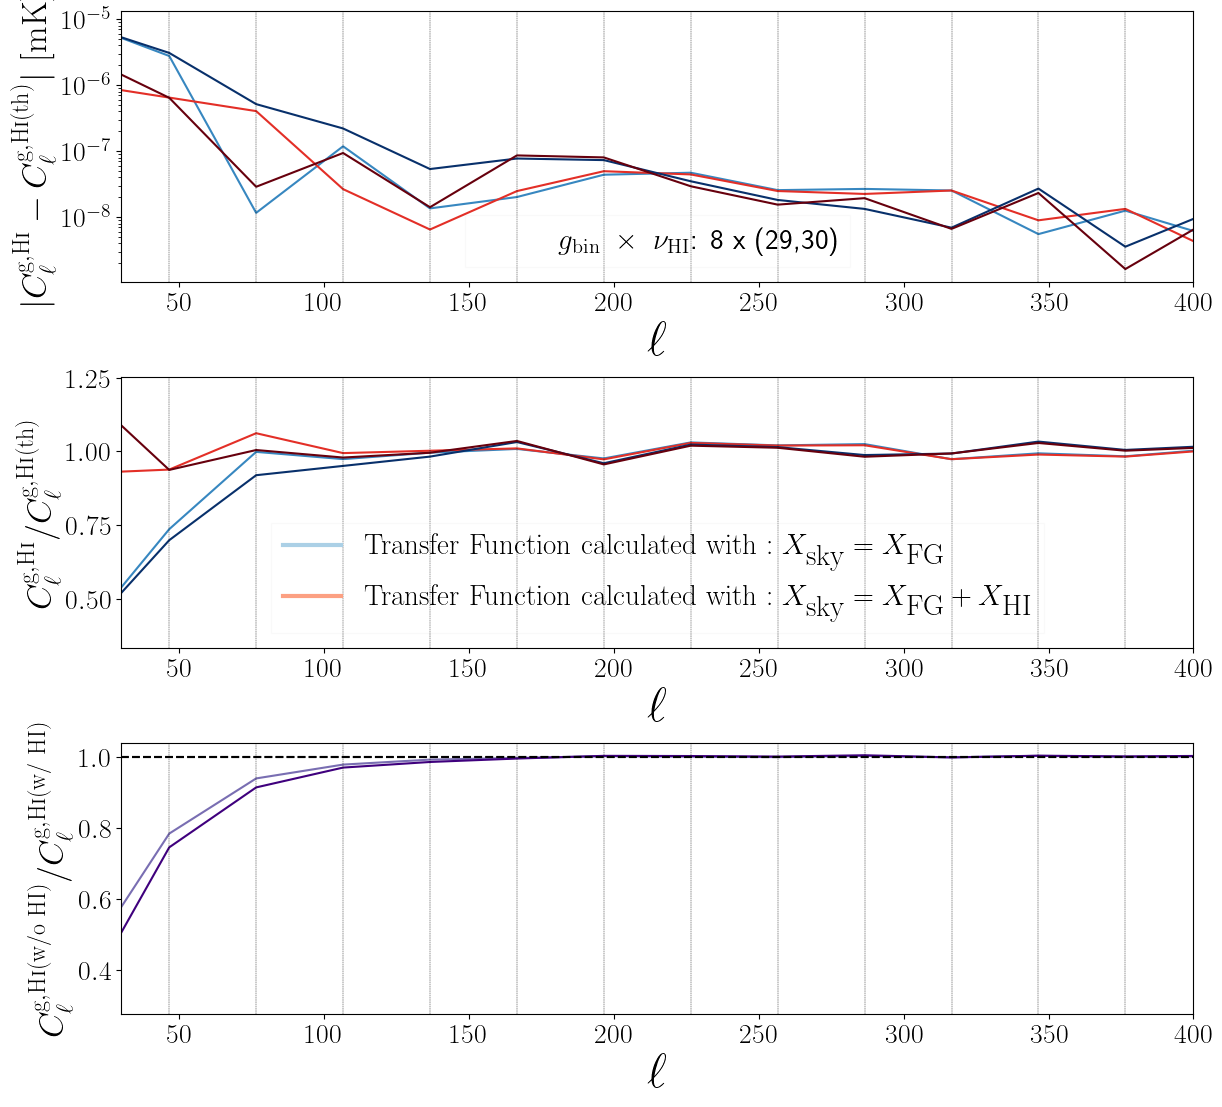

In [193]:
fig   = plt.figure()
grid  = plt.GridSpec(3,1,top=2.2,right=1.8, wspace=0.03, hspace=0.35)
############################################################
l = np.arange(3*256)#leff[filter_ell]
#index_range = [9-1,10-1]
N =len(index_range)
#N=len( get_hibins_from_gbin(gbin) ) + 1
#cmap_no  = cmc.berlin.resampled(N+1) 
cmap_no = plt.get_cmap("Blues"    , N+2)
#cmap_hi  = cmc.managua.resampled(N+1) 
cmap_hi = plt.get_cmap("Reds"    , N+2)

cmap = plt.get_cmap("Purples"    , N+2)
##########################################################
ax  = plt.subplot(grid[0]) 
index_str = "("; j=0
for i,hbin in enumerate(get_hibins_from_gbin(gbin)):
    if hbin in index_range:
        if index_str=="(":
            index_str += "{}".format(hbin+1)
        else:
            index_str += ",{}".format(hbin+1)    
        #print(gbin,hbin)
        cldeb_no = b.bin_cell( fact*CXproc[hbin,:]*TF_no[hbin,:] )
        cldeb_hi = b.bin_cell( fact*CXproc[hbin,:]*TF_hi[hbin,:] )
        clthr    = b.bin_cell( fact*CXthr[hbin,:] )
        chi2_hi  = np.sqrt( (cldeb_hi-clthr)**2 ) 
        chi2_no  = np.sqrt( (cldeb_no-clthr)**2 )   
        ax.plot(leff, chi2_no, color=cmap_no(j+2))#, s=100, marker='x')
        ax.plot(leff, chi2_hi, color=cmap_hi(j+2))#, s=100, marker='+')
        j+=1
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
index_str += ")"
ax.set_xlim(30,400)  
ax.set_ylabel(r'$|C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}-C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\textrm{(th)}}_{\ell}|\ \textrm{[mK]}$', fontsize=25)
ax.set_xlabel(r'$\ell$', fontsize=35)
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('log'); ax.set_xscale('linear')
##########################################################
ax  = plt.subplot(grid[1]) 
j=0
for i,hbin in enumerate(get_hibins_from_gbin(gbin)):
    if hbin in index_range:
        cldeb_no = b.bin_cell( fact*CXproc[hbin,:]*TF_no[hbin,:] )
        cldeb_hi = b.bin_cell( fact*CXproc[hbin,:]*TF_hi[hbin,:] )
        clthr    = b.bin_cell( fact*CXthr[hbin,:] )
        chi2_hi  = cldeb_hi/clthr
        chi2_no  = cldeb_no/clthr
        ax.plot(leff, chi2_no, color=cmap_no(j+2))#, s=100, marker='x')
        ax.plot(leff, chi2_hi, color=cmap_hi(j+2))#, s=100, marker='+')
        j+=1
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\textrm{(th)}}_{\ell}$', fontsize=25)
ax.set_xlabel(r'$\ell$', fontsize=35)
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('linear'); ax.set_xscale('linear')
###########################################################
ax  = plt.subplot(grid[2]) 
j=0
for i,hbin in enumerate(get_hibins_from_gbin(gbin)):
    if hbin in index_range:
        cldeb_no = b.bin_cell( fact*CXproc[hbin,:]*TF_no[hbin,:] )
        cldeb_hi = b.bin_cell( fact*CXproc[hbin,:]*TF_hi[hbin,:] )
        ax.plot(leff, cldeb_no/cldeb_hi, color=cmap(j+2))#, s=100, marker='x')
        ax.axhline(y=1,ls='dashed', color='black')
        j+=1
for l in leff: ax.axvline(x=l, c='black', ls='dashed', lw=0.3)
ax.set_xlim(30,400)  
ax.set_ylabel(r'$C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\textrm{(w/o HI)}}_{\ell}/C^{\LARGE{\textrm{g}},\LARGE{\textrm{H}\textsc{i}}\textrm{(w/ HI)}}_{\ell}$', fontsize=25)
ax.set_xlabel(r'$\ell$', fontsize=35)
#ax.set_ylim(1e-7,3e-5)  
ax.set_yscale('linear'); ax.set_xscale('linear')
###########################################################
ax  = plt.subplot(grid[0]) 

ax.legend([Patch(visible=False) ], [r"$g_{\rm bin}\ \times\ \nu_{\rm HI}$: "+"{} x {}".format(gbin+1,index_str)], ncols=1,
         fontsize=21, loc='lower center',framealpha=0.1, fancybox=False,
         #handletextpad=0.8, 
         columnspacing=1.1)

ax  = plt.subplot(grid[1]) 
custom_lines = [Line2D([], [], 
                             color    =cmap_no(N-1),
                             linewidth=3,#c_settings['thr']['lw'], 
                             linestyle='solid'),#c_settings['thr']['ls']),
                Line2D([], [], 
                             color    =cmap_hi(N-1),
                             linewidth=3,#c_settings['sim']['lw'], 
                             linestyle='solid',
                             alpha=1),
               ]
ax.legend(custom_lines, [r'${\rm Transfer\ Function\ calculated\ with}:\ $' + r'$X_\textrm{sky}=X_\textrm{FG}$',
                         r'${\rm Transfer\ Function\ calculated\ with}:\ $' + r'$X_\textrm{sky}=X_\textrm{FG}+X_\textrm{HI}$',
                        ], ncols=1,
         fontsize=21, loc='lower center',framealpha=0.1, fancybox=False,
         #handletextpad=0.8, 
         columnspacing=1.1)
###########################################################
plt.show()

In [9]:
TF_dict_hi[1].keys()

dict_keys(['tf_hi', 'tf_no', 'jsim0', 'CX', 'R', 'Xg', 'Xr'])

In [14]:
TF_dict_hi[1]['Xr']['mixmatrix'].shape

(30, 4)

In [15]:
TF_dict_hi[1]['tf_hi']

{'tf': array([[-5.43643954e+03,  4.29137997e-01,  6.75216596e-01, ...,
         -1.70113832e-02, -1.14219532e-02,  6.71173381e-03],
        [-4.20478820e+01,  1.33624212e+00,  1.15239175e+00, ...,
          4.34733692e-02, -1.49745839e-02,  3.91287391e-03],
        [-2.26435576e+03,  9.79254880e-01,  9.57903705e-01, ...,
         -1.09428222e-02, -2.06049771e-02,  1.28574988e-02],
        ...,
        [-3.23443773e+02,  8.56506029e-01,  7.34393335e-01, ...,
         -4.96507971e-02, -6.42076811e-03, -1.78931535e-02],
        [-9.43080659e+01,  6.93508804e-01,  9.14182738e-01, ...,
         -2.12590811e-02, -5.35024023e-03, -7.49433555e-02],
        [ 3.23771462e+02,  6.72206424e-01,  3.37149021e-01, ...,
         -2.27140941e-03,  1.88282191e-02, -1.87312782e-03]]),
 'errtf': array([[0.09083253, 0.09227898, 0.09105847, ..., 0.09899807, 0.09888678,
         0.0975401 ],
        [0.09200106, 0.09169638, 0.09081016, ..., 0.09887175, 0.09639063,
         0.09734755],
        [0.092754  , 0